# Week 4 - Machine Learning Model Development and Evaluation

**Dataset:** cleaned IBM Telco Customer Churn data from Week 1 (7,043 customers).

This notebook runs `src/06_modeling.py`: a churn classifier built with scikit-learn
pipelines (logistic regression as the main model, a tuned decision tree for
comparison, and a majority-class baseline), evaluated with stratified
cross-validation and on a held-out test set. The code cells are taken directly
from `src/`.


In [1]:
import sys
sys.path.insert(0, "../src")  # make the project modules in src/ importable
%config InlineBackend.figure_format = 'retina'

## Week 4 - Churn prediction model

**Task:** binary classification - predict `churn_flag` (1 = the customer left).

**Plan**
1. Prepare features (stateless transformations only, so they cannot leak information).
2. Hold out a stratified 20% test set (random_state = 42). It is used once, at the end.
3. Compare candidate feature sets and models with stratified 5-fold cross-validation
   on the training set only. All preprocessing sits inside scikit-learn pipelines,
   so scaling and encoding are fitted on the training folds of each split.
4. Choose a decision threshold from out-of-fold predictions on the training set.
5. Evaluate once on the test set: metrics, confusion matrix, ROC and PR curves.
6. Diagnose: learning curves, calibration, coefficients and error analysis.

In [2]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, make_scorer, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from config import MODEL_DIR, RANDOM_SEED, RESULTS_DIR, TABLE_DIR
from data_utils import ADDON_COLUMNS, load_clean_data
from plot_style import (CHURN_COLOR, INK, MUTED_INK, ORDINAL_BLUES, RETAINED_COLOR, SEQUENTIAL_CMAP,
                        apply_style, save_figure)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
apply_style()
df = load_clean_data()
results = {"random_seed": RANDOM_SEED}

### 1. Data preparation and feature engineering

* **Target:** `churn_flag` (26.5% positive - the classes are imbalanced).
* **Excluded:** `customerID` (an identifier) and `Churn` (the target in text form -
  keeping it would leak the answer).
* **Redundant labels:** "No internet service" / "No phone service" repeat what
  `InternetService` / `PhoneService` already say, so they are recoded to "No".
* **Candidate engineered feature:** `log_tenure` = log(1 + tenure), because Weeks 2-3
  showed churn falling steeply in the first months and more slowly after.

These are row-by-row transformations with no fitted parameters, so applying
them before the split cannot leak information from the test set.

In [3]:
def prepare_features(frame):
    """Stateless feature preparation applied identically to every row."""
    out = frame.copy()
    for column in ADDON_COLUMNS:
        out[column] = out[column].astype(str).replace("No internet service", "No")
    out["MultipleLines"] = out["MultipleLines"].astype(str).replace("No phone service", "No")
    out["log_tenure"] = np.log1p(out["tenure"])
    return out


data = prepare_features(df)
y = data["churn_flag"].to_numpy()

CATEGORICAL = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
               "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
               "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
NUMERIC_BASE = ["tenure", "MonthlyCharges", "TotalCharges"]
print(f"Rows: {len(data):,} | positive class share: {y.mean():.1%}")
print(f"Categorical predictors: {len(CATEGORICAL)} | numeric candidates: {NUMERIC_BASE + ['log_tenure']}")


def make_preprocessor(numeric_columns):
    """Scale numeric columns; one-hot encode categoricals (first level dropped as reference)."""
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])


def make_logistic(numeric_columns, class_weight=None):
    return Pipeline([("preprocess", make_preprocessor(numeric_columns)),
                     ("model", LogisticRegression(C=1.0, max_iter=2000, class_weight=class_weight))])

Rows: 7,043 | positive class share: 26.5%
Categorical predictors: 16 | numeric candidates: ['tenure', 'MonthlyCharges', 'TotalCharges', 'log_tenure']


### 2. Train/test split

80% training / 20% test, stratified on the target so both parts keep the
26.5% churn rate, with a fixed random_state for reproducibility.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    data, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED)
print(f"Training set: {len(X_train):,} rows, churn rate {y_train.mean():.2%}")
print(f"Test set    : {len(X_test):,} rows, churn rate {y_test.mean():.2%}")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
results["split"] = {"train_rows": len(X_train), "test_rows": len(X_test),
                    "train_churn_rate": round(float(y_train.mean()), 4),
                    "test_churn_rate": round(float(y_test.mean()), 4),
                    "test_size": 0.20, "stratified": True, "cv_folds": 5}

Training set: 5,634 rows, churn rate 26.54%
Test set    : 1,409 rows, churn rate 26.54%


### 3. Feature selection with cross-validation (training set only)

Two questions: does `TotalCharges` add anything beyond `tenure` and
`MonthlyCharges` (Week 1: r = 0.83 with tenure), and does `log_tenure` help?
Each candidate logistic regression is scored by 5-fold CV ROC-AUC.

In [5]:
feature_sets = {
    "base (tenure, MonthlyCharges, TotalCharges)": NUMERIC_BASE,
    "base without TotalCharges": ["tenure", "MonthlyCharges"],
    "base + log_tenure": NUMERIC_BASE + ["log_tenure"],
    "without TotalCharges + log_tenure": ["tenure", "MonthlyCharges", "log_tenure"],
}
selection_rows = []
for name, numeric_columns in feature_sets.items():
    scores = cross_validate(make_logistic(numeric_columns), X_train, y_train, cv=cv, scoring="roc_auc")
    selection_rows.append({"feature_set": name, "numeric_features": ", ".join(numeric_columns),
                           "cv_roc_auc_mean": scores["test_score"].mean(),
                           "cv_roc_auc_sd": scores["test_score"].std()})
selection = pd.DataFrame(selection_rows)
display(selection.round(4))

# Rule set before looking at the scores: take the best mean CV ROC-AUC; if a
# smaller feature set is within 0.001 of the best, prefer the smaller set.
best_score = selection["cv_roc_auc_mean"].max()
candidates = selection[selection["cv_roc_auc_mean"] >= best_score - 0.001].copy()
candidates["n_numeric"] = candidates["feature_set"].map(lambda k: len(feature_sets[k]))
chosen_set = candidates.sort_values(["n_numeric", "cv_roc_auc_mean"], ascending=[True, False]).iloc[0]["feature_set"]
NUMERIC = feature_sets[chosen_set]
print("Chosen feature set:", chosen_set, "->", NUMERIC)
selection.to_csv(TABLE_DIR / "feature_set_comparison_cv.csv", index=False)
results["feature_selection"] = {"table": selection.round(5).to_dict("records"), "chosen": chosen_set,
                                "numeric_features": NUMERIC, "categorical_features": CATEGORICAL}

,feature_set,numeric_features,cv_roc_auc_mean,cv_roc_auc_sd
0,"base (tenure, MonthlyCharges, TotalCharges)","tenure, MonthlyCharges, TotalCharges",0.8460,0.0126
1,base without TotalCharges,"tenure, MonthlyCharges",0.8448,0.0121
2,base + log_tenure,"tenure, MonthlyCharges, TotalCharges, log_tenure",0.8502,0.0115
3,without TotalCharges + log_tenure,"tenure, MonthlyCharges, log_tenure",0.8502,0.0116


Chosen feature set: without TotalCharges + log_tenure -> ['tenure', 'MonthlyCharges', 'log_tenure']


### 4. Models and cross-validation

* **Baseline:** always predict "no churn" (majority class) - shows what accuracy
  alone would reward.
* **Logistic regression (main model):** interpretable (coefficients -> odds
  ratios), well calibrated, a standard first model for a binary outcome.
  Default L2 regularisation, C = 1.0.
* **Logistic regression, class_weight="balanced":** a tested option for the class imbalance.
* **Decision tree:** a simple non-linear comparison; depth and leaf size tuned by
  5-fold CV (ROC-AUC) on the training set to limit overfitting.

In [6]:
logistic = make_logistic(NUMERIC)
logistic_balanced = make_logistic(NUMERIC, class_weight="balanced")
baseline = Pipeline([("preprocess", make_preprocessor(NUMERIC)),
                     ("model", DummyClassifier(strategy="most_frequent"))])

tree_search = GridSearchCV(
    Pipeline([("preprocess", make_preprocessor(NUMERIC)),
              ("model", DecisionTreeClassifier(random_state=RANDOM_SEED))]),
    param_grid={"model__max_depth": [3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 20, 50]},
    scoring="roc_auc", cv=cv, n_jobs=1)
tree_search.fit(X_train, y_train)
tree = tree_search.best_estimator_
print("Decision tree - best parameters:", tree_search.best_params_,
      f"(CV ROC-AUC {tree_search.best_score_:.4f})")

# zero_division=0: the baseline never predicts churn, so its precision/F1 are defined as 0
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": make_scorer(f1_score, zero_division=0), "roc_auc": "roc_auc"}
cv_rows = []
for name, model in [("Baseline (majority class)", baseline), ("Logistic regression", logistic),
                    ("Logistic regression (balanced)", logistic_balanced), ("Decision tree (tuned)", tree)]:
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    row = {"model": name}
    for metric in scoring:
        row[f"cv_{metric}"] = scores[f"test_{metric}"].mean()
        row[f"cv_{metric}_sd"] = scores[f"test_{metric}"].std()
        row[f"train_{metric}"] = scores[f"train_{metric}"].mean()
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows)
display(cv_results[["model", "cv_accuracy", "cv_precision", "cv_recall", "cv_f1", "cv_roc_auc",
                    "cv_roc_auc_sd", "train_roc_auc"]].round(4))
cv_results.to_csv(TABLE_DIR / "cross_validation_results.csv", index=False)
results["cv"] = cv_results.round(5).to_dict("records")
results["tree_best_params"] = {k.replace("model__", ""): v for k, v in tree_search.best_params_.items()}
results["tree_best_cv_auc"] = round(float(tree_search.best_score_), 5)
grid = pd.DataFrame(tree_search.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf",
                                              "mean_test_score", "std_test_score"]]
grid.to_csv(TABLE_DIR / "decision_tree_grid_search.csv", index=False)

Decision tree - best parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 50} (CV ROC-AUC 0.8302)


,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_roc_auc_sd,train_roc_auc
0,Baseline (majority class),0.7346,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000
1,Logistic regression,0.8081,0.6732,0.5385,0.5980,0.8502,0.0116,0.8542
2,Logistic regression (balanced),0.7549,0.5250,0.8007,0.6341,0.8501,0.0116,0.8542
3,Decision tree (tuned),0.7870,0.6346,0.4876,0.5479,0.8302,0.0110,0.8553


### 5. Decision threshold (chosen on training data, not the test set)

A predicted probability above 0.5 is the default cut-off for "churn", but with
a 26.5% positive rate this favours precision over recall. Out-of-fold
probabilities from 5-fold CV on the training set show how precision, recall
and F1 change with the threshold. The threshold with the highest F1 is chosen.

In [7]:
oof_probability = cross_val_predict(logistic, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)
threshold_table = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_train, oof_probability >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_train, oof_probability >= t) for t in thresholds],
    "f1": [f1_score(y_train, oof_probability >= t) for t in thresholds],
})
best_threshold = float(threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"])
display(threshold_table[threshold_table["threshold"].isin([0.2, 0.3, best_threshold, 0.4, 0.5, 0.6])].round(4))
print(f"Threshold with the highest out-of-fold F1: {best_threshold:.2f}")
threshold_table.to_csv(TABLE_DIR / "threshold_analysis_oof.csv", index=False)
results["threshold"] = {"chosen": best_threshold,
                        "oof_at_chosen": threshold_table.set_index("threshold").loc[best_threshold].round(4).to_dict(),
                        "oof_at_0.5": threshold_table.set_index("threshold").loc[0.5].round(4).to_dict()}

,threshold,precision,recall,f1
10,0.20,0.4781,0.8696,0.6170
20,0.30,0.5414,0.7565,0.6311
24,0.34,0.5728,0.7211,0.6384
30,0.40,0.6108,0.6562,0.6327
40,0.50,0.6731,0.5385,0.5983
50,0.60,0.7206,0.3813,0.4987


Threshold with the highest out-of-fold F1: 0.34


### 6. Final training and test-set evaluation

The models are refitted on the full training set and evaluated once on the
1,409 held-out customers.

In [8]:
logistic.fit(X_train, y_train)
logistic_balanced.fit(X_train, y_train)
baseline.fit(X_train, y_train)

probabilities = {
    "Baseline (majority class)": baseline.predict_proba(X_test)[:, 1],
    "Logistic regression": logistic.predict_proba(X_test)[:, 1],
    "Logistic regression (balanced)": logistic_balanced.predict_proba(X_test)[:, 1],
    "Decision tree (tuned)": tree.predict_proba(X_test)[:, 1],
}


def evaluate(name, probability, threshold):
    predicted = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    return {"model": name, "threshold": threshold,
            "accuracy": accuracy_score(y_test, predicted),
            "precision": precision_score(y_test, predicted, zero_division=0),
            "recall": recall_score(y_test, predicted), "f1": f1_score(y_test, predicted, zero_division=0),
            "roc_auc": roc_auc_score(y_test, probability),
            "pr_auc": average_precision_score(y_test, probability),
            "brier": brier_score_loss(y_test, probability),
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


test_rows = [evaluate(name, p, 0.5) for name, p in probabilities.items()]
test_rows.append(evaluate(f"Logistic regression (threshold {best_threshold:.2f})",
                          probabilities["Logistic regression"], best_threshold))
test_results = pd.DataFrame(test_rows)
display(test_results.round(4))
test_results.to_csv(TABLE_DIR / "test_set_metrics.csv", index=False)
results["test"] = test_results.round(5).to_dict("records")

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,tp,fp,fn,tn
0,Baseline (majority class),0.50,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654,0.2654,0,0,374,1035
1,Logistic regression,0.50,0.8048,0.6678,0.5267,0.5889,0.8481,0.6650,0.1345,197,98,177,937
2,Logistic regression (balanced),0.50,0.7402,0.5068,0.7968,0.6195,0.8482,0.6650,0.1642,298,290,76,745
3,Decision tree (tuned),0.50,0.7999,0.7091,0.4171,0.5253,0.8277,0.6259,0.1419,156,64,218,971
4,Logistic regression (threshold 0.34),0.34,0.7800,0.5667,0.7273,0.6370,0.8481,0.6650,0.1345,272,208,102,827


Saved figure: outputs/figures/fig4_1_confusion_matrices.png


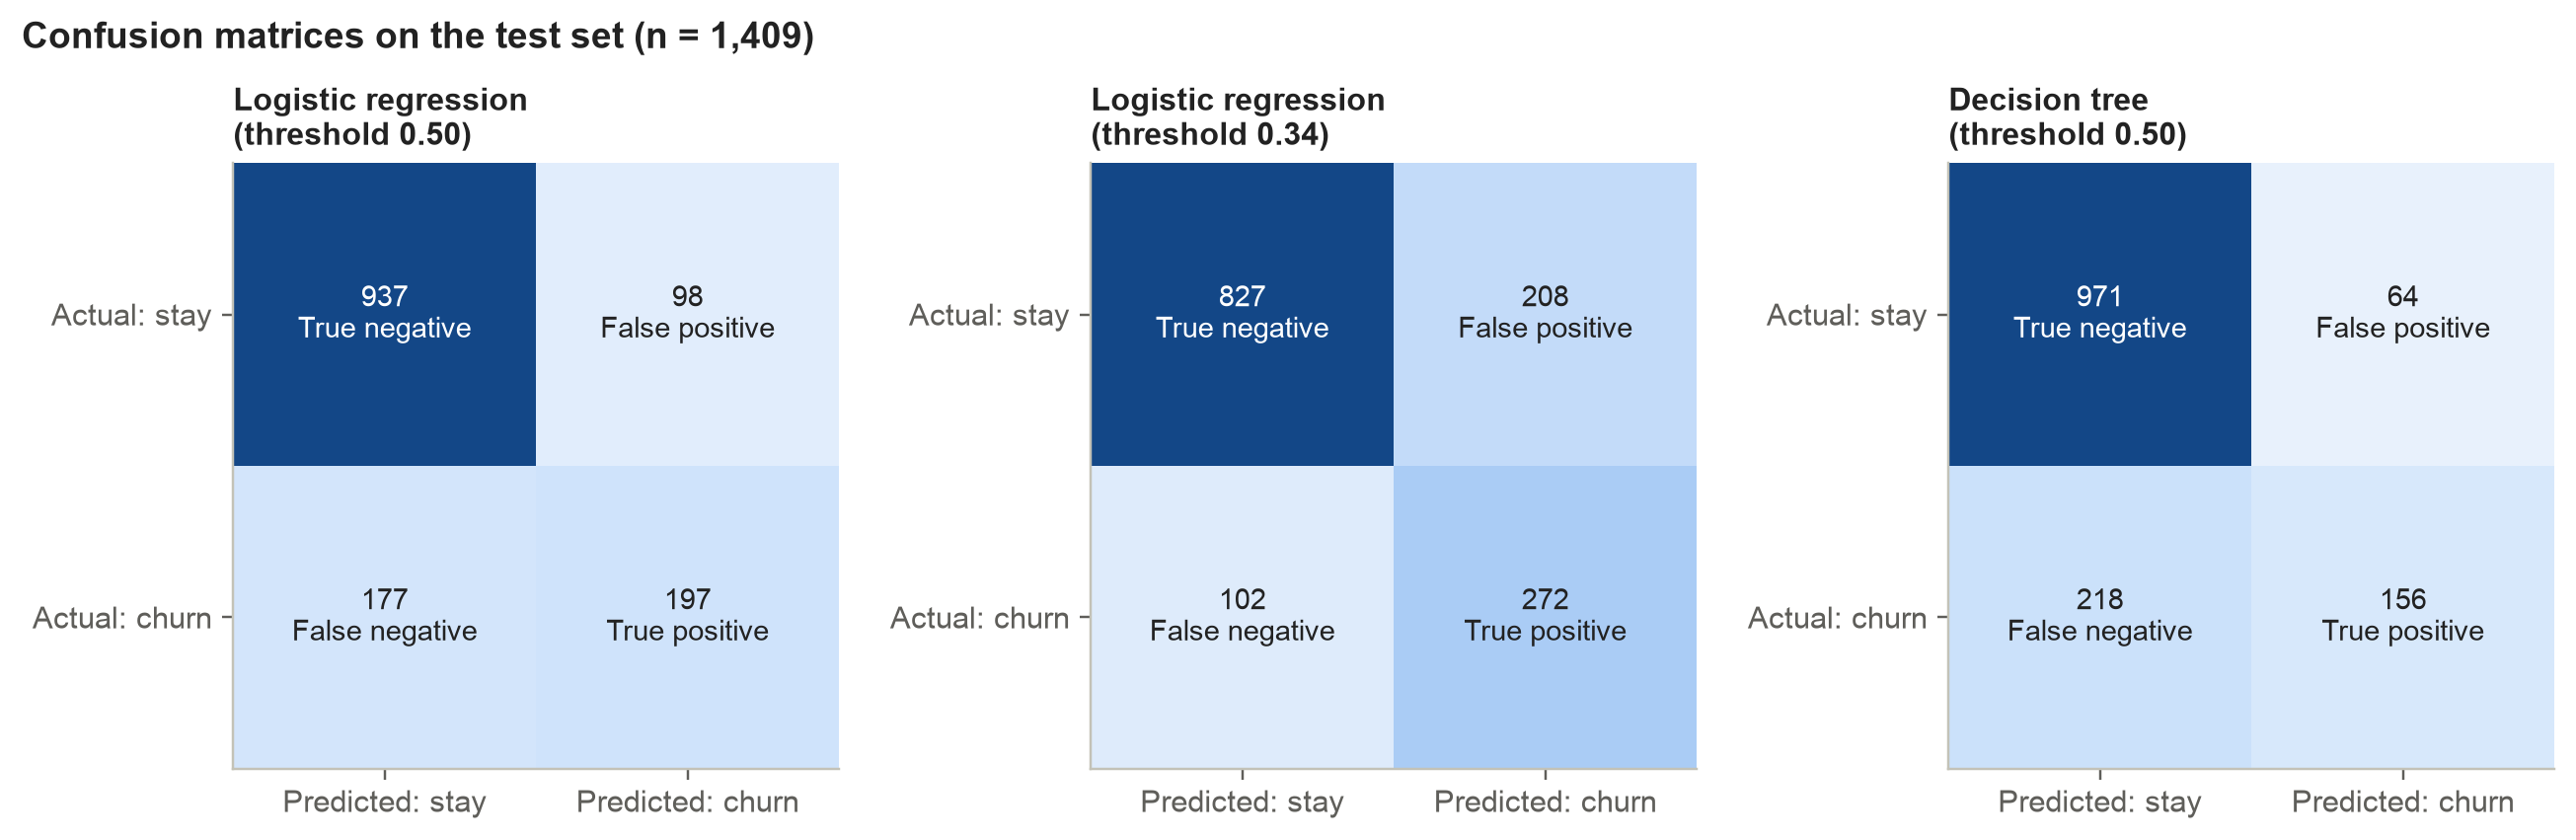

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
panels = [("Logistic regression", 0.5, "Logistic regression\n(threshold 0.50)"),
          ("Logistic regression", best_threshold, f"Logistic regression\n(threshold {best_threshold:.2f})"),
          ("Decision tree (tuned)", 0.5, "Decision tree\n(threshold 0.50)")]
for ax, (name, threshold, title) in zip(axes, panels):
    matrix = confusion_matrix(y_test, (probabilities[name] >= threshold).astype(int))
    ax.imshow(matrix, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=matrix.max() * 1.1)
    labels = [["True negative", "False positive"], ["False negative", "True positive"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]:,}\n{labels[i][j]}", ha="center", va="center", fontsize=9.5,
                    color="white" if matrix[i, j] > matrix.max() * 0.6 else INK)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Predicted: stay", "Predicted: churn"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Actual: stay", "Actual: churn"])
    ax.set_title(title, fontsize=10.5)
    ax.grid(False)
fig.suptitle(f"Confusion matrices on the test set (n = {len(y_test):,})", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save_figure(fig, "fig4_1_confusion_matrices.png")

Saved figure: outputs/figures/fig4_2_roc_and_pr_curves.png


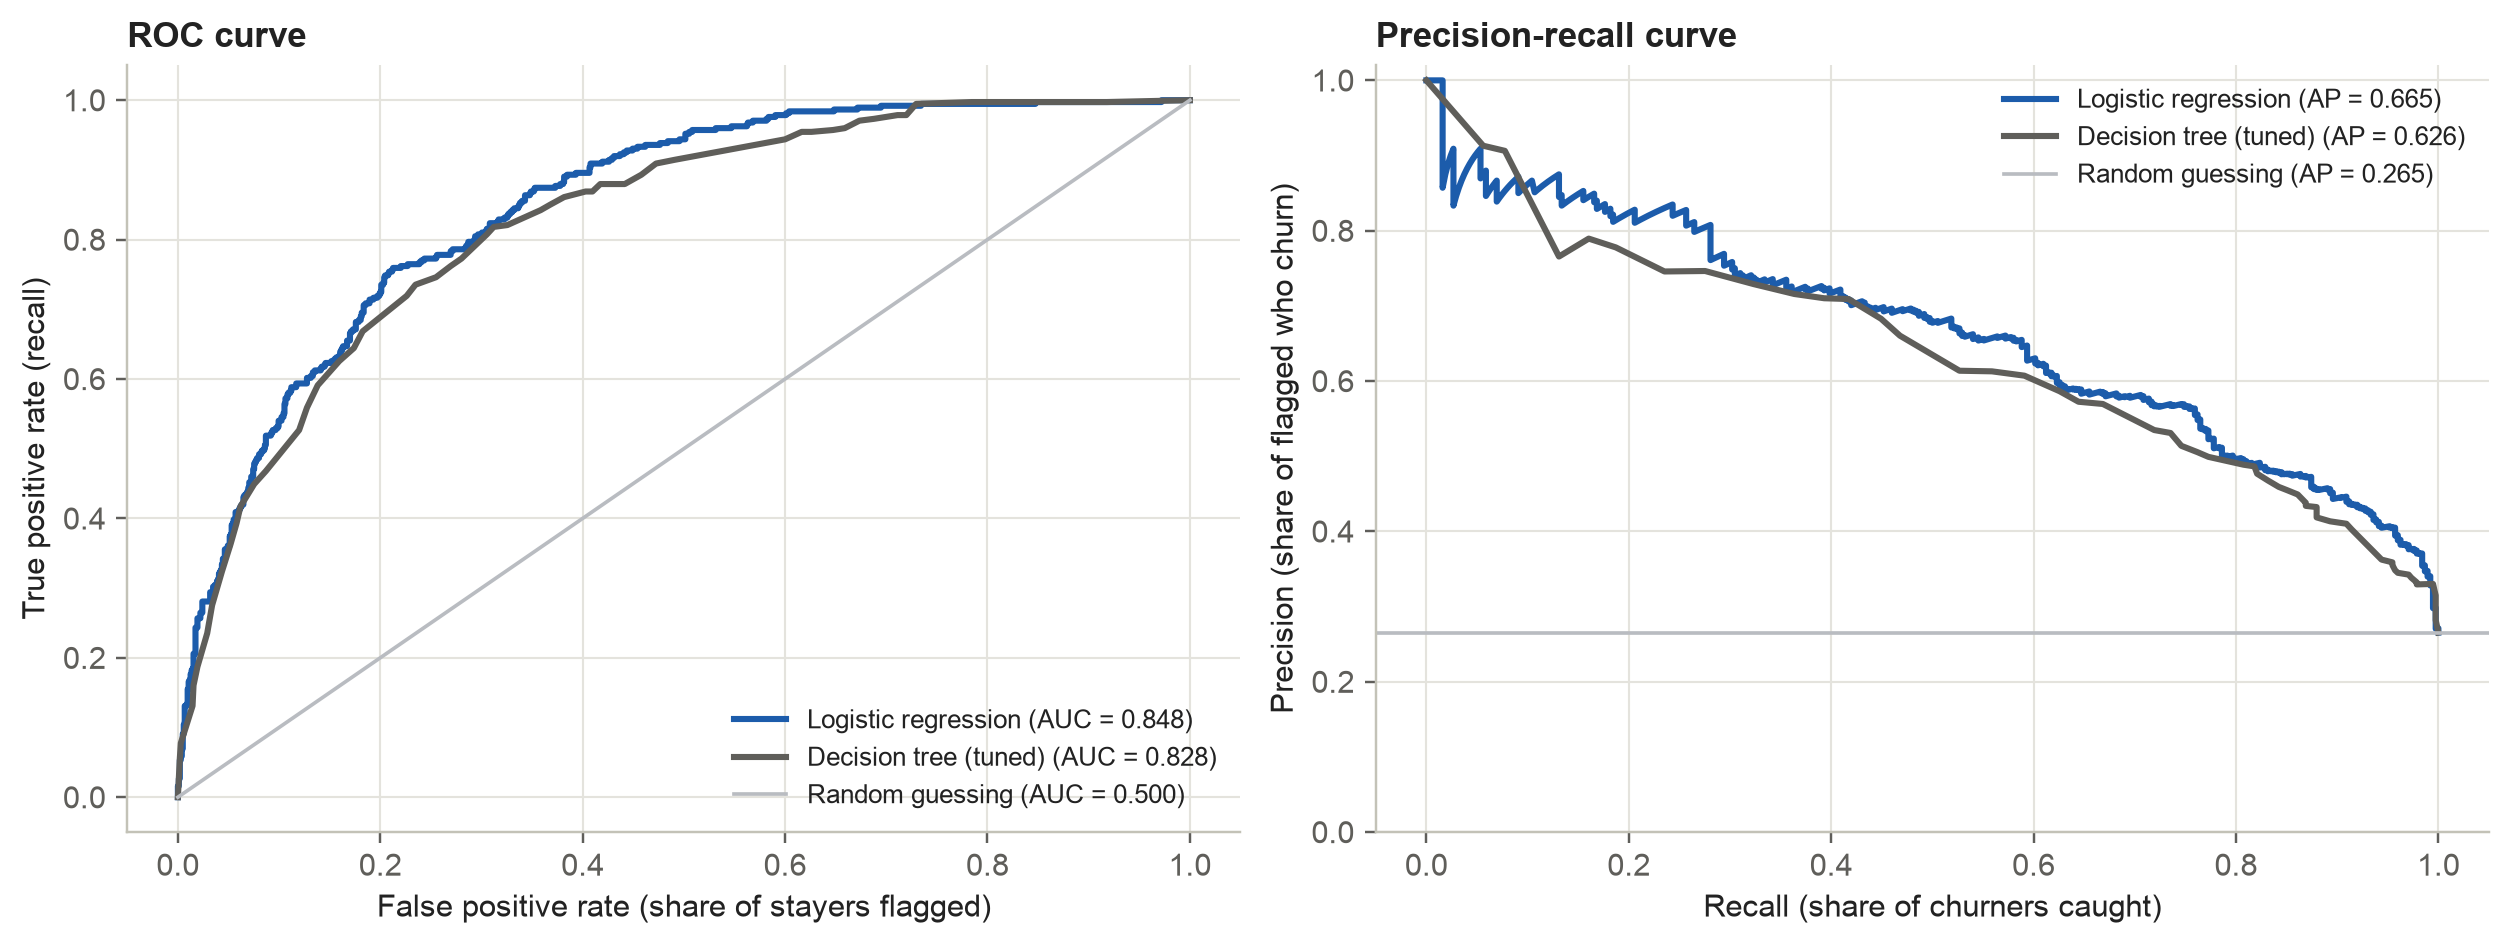

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
styles = {"Logistic regression": (CHURN_COLOR, "-"), "Decision tree (tuned)": (MUTED_INK, "-")}
ax = axes[0]
for name, (colour, line) in styles.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    ax.plot(fpr, tpr, color=colour, linestyle=line, linewidth=2,
            label=f"{name} (AUC = {roc_auc_score(y_test, probabilities[name]):.3f})")
ax.plot([0, 1], [0, 1], color=RETAINED_COLOR, linewidth=1.2, label="Random guessing (AUC = 0.500)")
ax.set_xlabel("False positive rate (share of stayers flagged)")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve")
ax.legend(loc="lower right", fontsize=8.5)
ax = axes[1]
for name, (colour, line) in styles.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities[name])
    ax.plot(recall, precision, color=colour, linestyle=line, linewidth=2,
            label=f"{name} (AP = {average_precision_score(y_test, probabilities[name]):.3f})")
ax.axhline(y_test.mean(), color=RETAINED_COLOR, linewidth=1.2, label=f"Random guessing (AP = {y_test.mean():.3f})")
ax.set_xlabel("Recall (share of churners caught)")
ax.set_ylabel("Precision (share of flagged who churn)")
ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curve")
ax.legend(loc="upper right", fontsize=8.5)
fig.tight_layout()
save_figure(fig, "fig4_2_roc_and_pr_curves.png")

Saved figure: outputs/figures/fig4_3_threshold_analysis.png


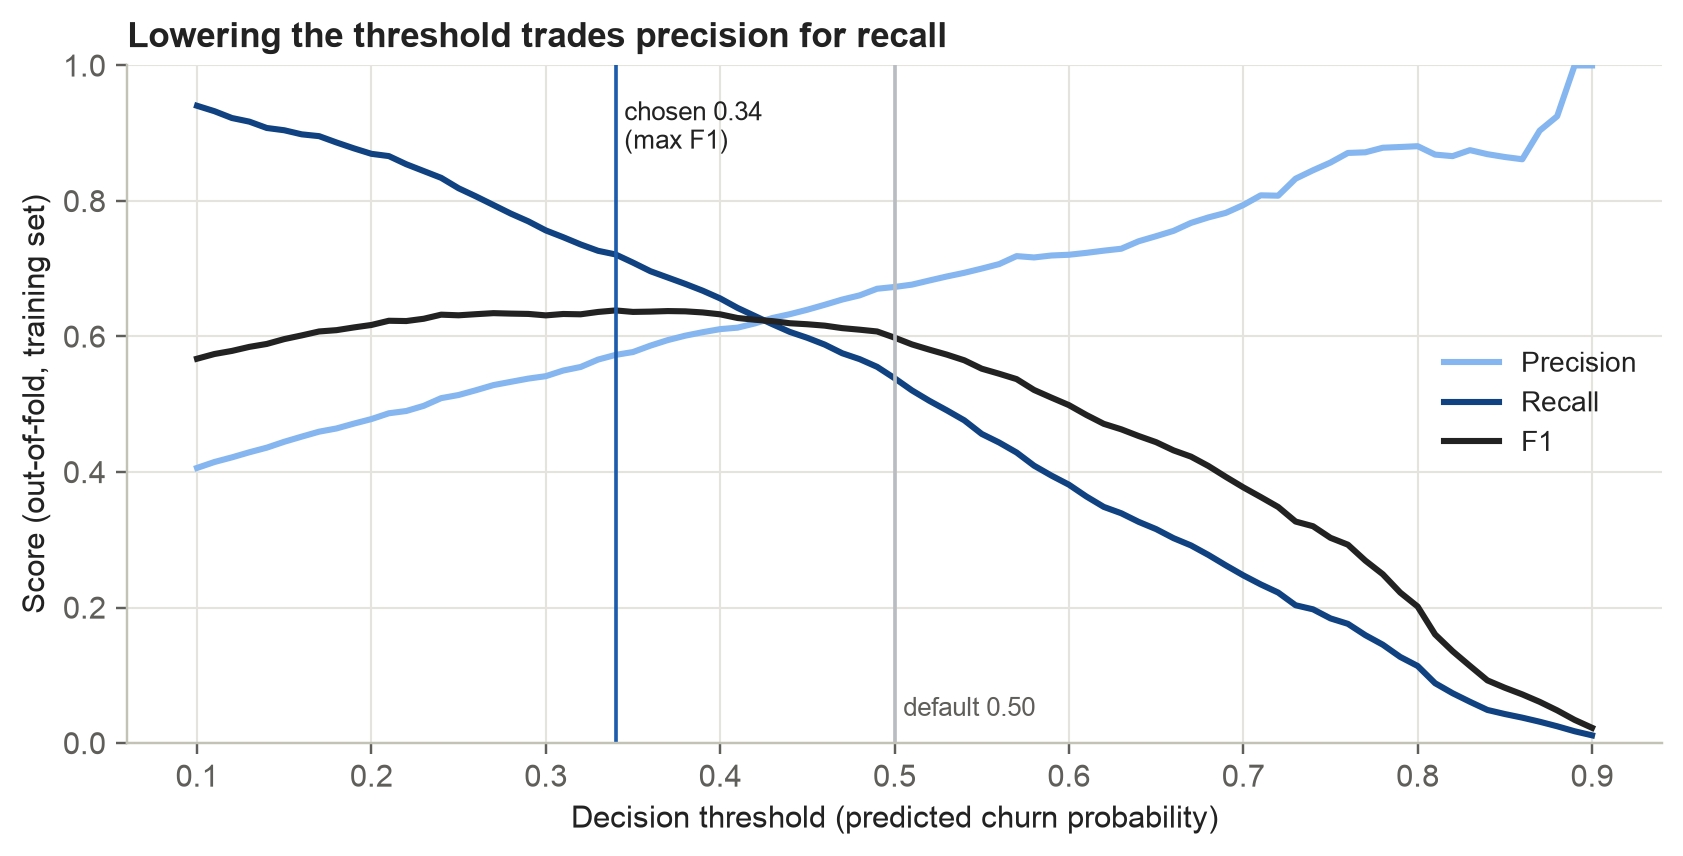

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(threshold_table["threshold"], threshold_table["precision"], color=ORDINAL_BLUES[0], linewidth=2, label="Precision")
ax.plot(threshold_table["threshold"], threshold_table["recall"], color=ORDINAL_BLUES[2], linewidth=2, label="Recall")
ax.plot(threshold_table["threshold"], threshold_table["f1"], color=INK, linewidth=2, label="F1")
ax.axvline(0.5, color=RETAINED_COLOR, linewidth=1.2)
ax.axvline(best_threshold, color=CHURN_COLOR, linewidth=1.2)
ax.text(0.505, 0.04, "default 0.50", fontsize=8.5, color=MUTED_INK)
ax.text(best_threshold + 0.005, 0.95, f"chosen {best_threshold:.2f}\n(max F1)", fontsize=8.5, color=INK, va="top")
ax.set_xlabel("Decision threshold (predicted churn probability)")
ax.set_ylabel("Score (out-of-fold, training set)")
ax.set_ylim(0, 1)
ax.set_title("Lowering the threshold trades precision for recall")
ax.legend(loc="center right")
save_figure(fig, "fig4_3_threshold_analysis.png")

### 7. Diagnostics: overfitting, underfitting and calibration

In [12]:
sizes = np.linspace(0.1, 1.0, 8)
curves = {}
for name, model in [("Logistic regression", make_logistic(NUMERIC)), ("Decision tree (tuned)", tree)]:
    train_sizes, train_scores, valid_scores = learning_curve(
        model, X_train, y_train, train_sizes=sizes, cv=cv, scoring="roc_auc", n_jobs=1)
    curves[name] = pd.DataFrame({"train_size": train_sizes, "train_auc": train_scores.mean(axis=1),
                                 "validation_auc": valid_scores.mean(axis=1),
                                 "validation_sd": valid_scores.std(axis=1)})
    print(name)
    display(curves[name].iloc[[0, 3, -1]].round(4))
pd.concat(curves, names=["model"]).to_csv(TABLE_DIR / "learning_curves.csv")
results["learning_curves"] = {k: v.round(5).to_dict("records") for k, v in curves.items()}

Logistic regression


,train_size,train_auc,validation_auc,validation_sd
0,450,0.8964,0.8349,0.0112
3,2189,0.8690,0.8483,0.0109
7,4507,0.8542,0.8502,0.0116


Decision tree (tuned)


,train_size,train_auc,validation_auc,validation_sd
0,450,0.8449,0.7844,0.0097
3,2189,0.8623,0.8179,0.0139
7,4507,0.8553,0.8302,0.0110


Saved figure: outputs/figures/fig4_4_learning_curves_and_calibration.png


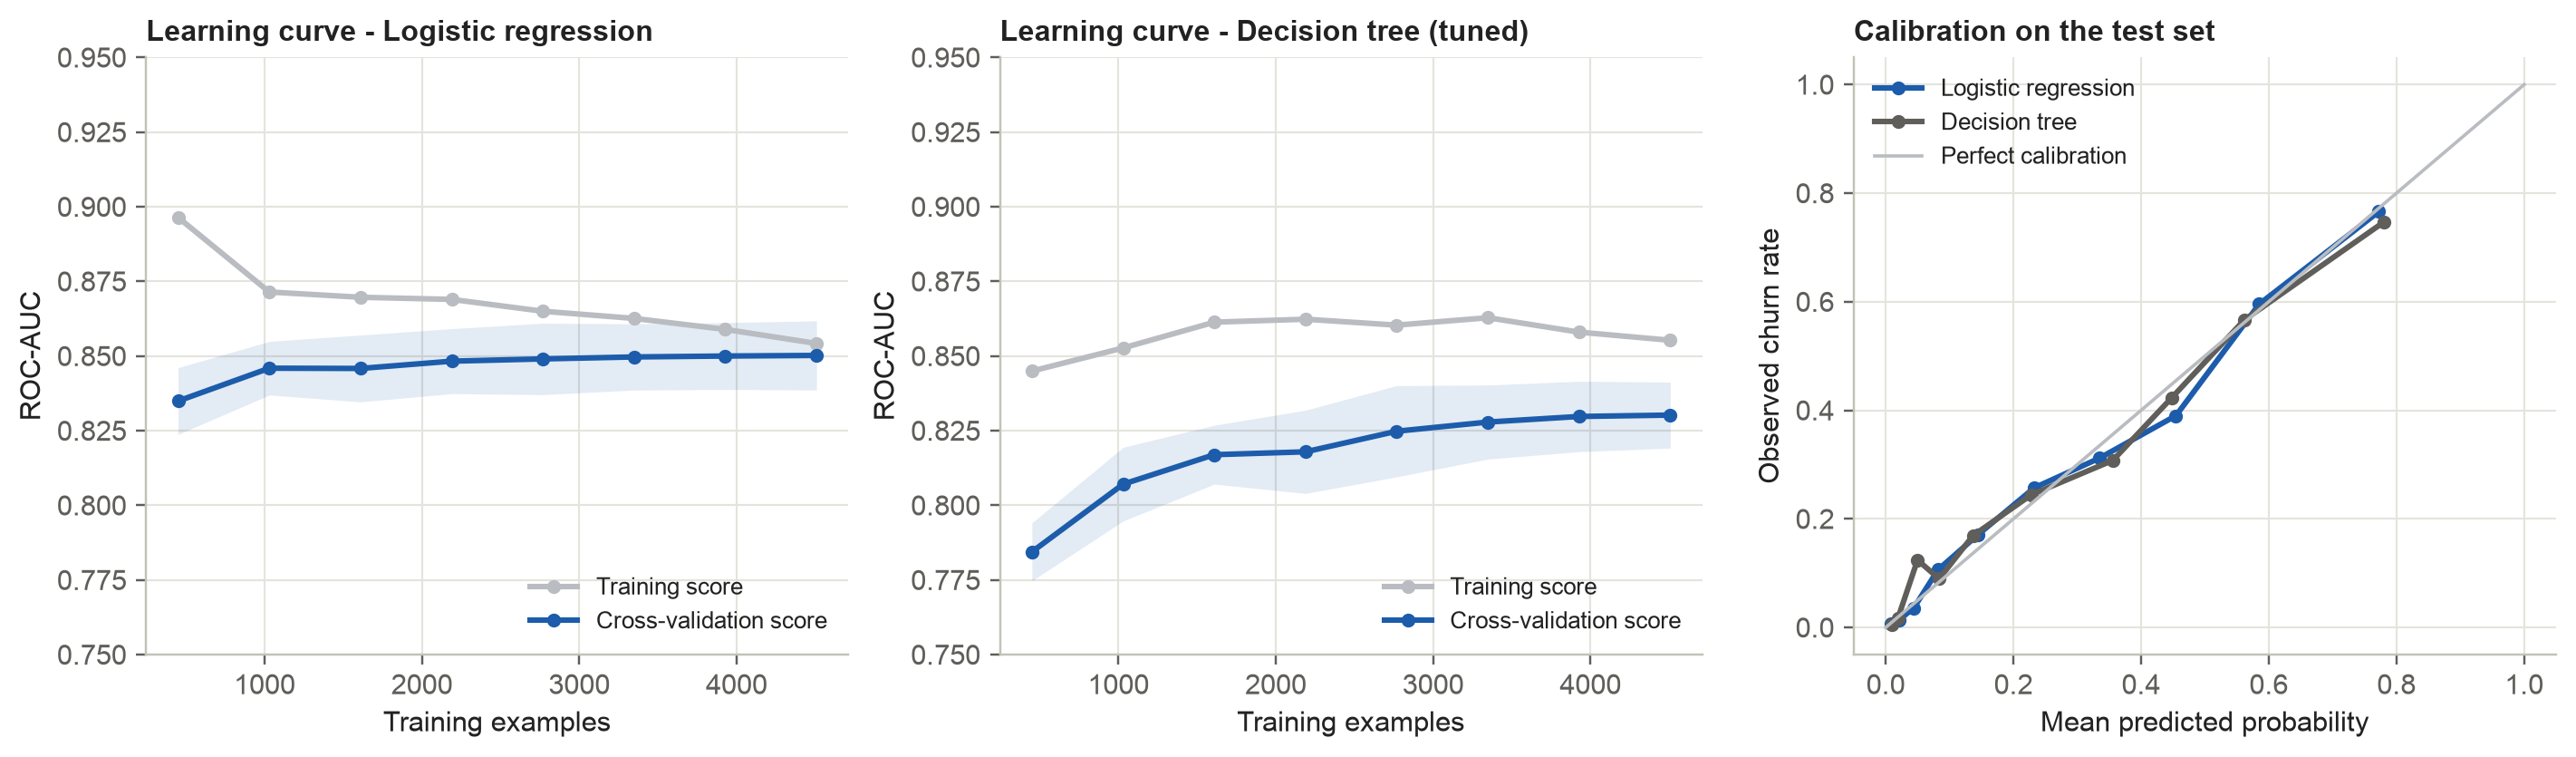

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (name, curve) in zip(axes[:2], curves.items()):
    ax.plot(curve["train_size"], curve["train_auc"], color=RETAINED_COLOR, linewidth=2, marker="o",
            markersize=4, label="Training score")
    ax.plot(curve["train_size"], curve["validation_auc"], color=CHURN_COLOR, linewidth=2, marker="o",
            markersize=4, label="Cross-validation score")
    ax.fill_between(curve["train_size"], curve["validation_auc"] - curve["validation_sd"],
                    curve["validation_auc"] + curve["validation_sd"], color=CHURN_COLOR, alpha=0.12, linewidth=0)
    ax.set_ylim(0.75, 0.95)
    ax.set_xlabel("Training examples")
    ax.set_ylabel("ROC-AUC")
    ax.set_title(f"Learning curve - {name}", fontsize=10.5)
    ax.legend(loc="lower right", fontsize=8.5)
ax = axes[2]
for name, (colour, _) in styles.items():
    observed_rate, predicted_rate = calibration_curve(y_test, probabilities[name], n_bins=10, strategy="quantile")
    ax.plot(predicted_rate, observed_rate, color=colour, marker="o", markersize=4, linewidth=2,
            label=f"{name.split(' (')[0]}")
ax.plot([0, 1], [0, 1], color=RETAINED_COLOR, linewidth=1.2, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Calibration on the test set", fontsize=10.5)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
save_figure(fig, "fig4_4_learning_curves_and_calibration.png")

### 8. What does the logistic regression rely on?

Coefficients are on the log-odds scale; exp(coefficient) is an odds ratio.
Numeric features were standardised, so their odds ratios are per one standard
deviation. Each categorical level is compared with its reference level
(the first category, e.g. Contract = Month-to-month). These are associations
conditional on the other features, not causal effects.

In [14]:
feature_names = logistic.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.DataFrame({"feature": [f.split("__", 1)[1] for f in feature_names],
                             "coefficient": logistic.named_steps["model"].coef_[0]})
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients = coefficients.reindex(coefficients["coefficient"].abs().sort_values(ascending=False).index)
display(coefficients.head(12).round(3))
coefficients.to_csv(TABLE_DIR / "logistic_regression_coefficients.csv", index=False)
results["coefficients"] = coefficients.round(5).to_dict("records")
results["intercept"] = round(float(logistic.named_steps["model"].intercept_[0]), 5)

tree_importance = pd.Series(tree.named_steps["model"].feature_importances_,
                            index=[f.split("__", 1)[1] for f in feature_names]).sort_values(ascending=False)
display(tree_importance.head(8).round(3).to_frame("importance"))
tree_importance.to_csv(TABLE_DIR / "decision_tree_feature_importance.csv", header=["importance"])
results["tree_importance_top"] = tree_importance.head(8).round(5).to_dict()

,feature,coefficient,odds_ratio
18,Contract_Two year,-1.628,0.196
9,InternetService_Fiber optic,1.112,3.039
10,InternetService_No,-1.005,0.366
2,log_tenure,-0.818,0.441
17,Contract_One year,-0.716,0.489
8,MultipleLines_Yes,0.426,1.530
19,PaperlessBilling_Yes,0.388,1.474
16,StreamingMovies_Yes,0.385,1.469
15,StreamingTV_Yes,0.380,1.462
7,PhoneService_Yes,-0.373,0.689


,importance
tenure,0.365
InternetService_Fiber optic,0.342
log_tenure,0.091
MonthlyCharges,0.044
PaymentMethod_Electronic check,0.037
InternetService_No,0.036
MultipleLines_Yes,0.022
Contract_Two year,0.019


Saved figure: outputs/figures/fig4_5_logistic_odds_ratios.png


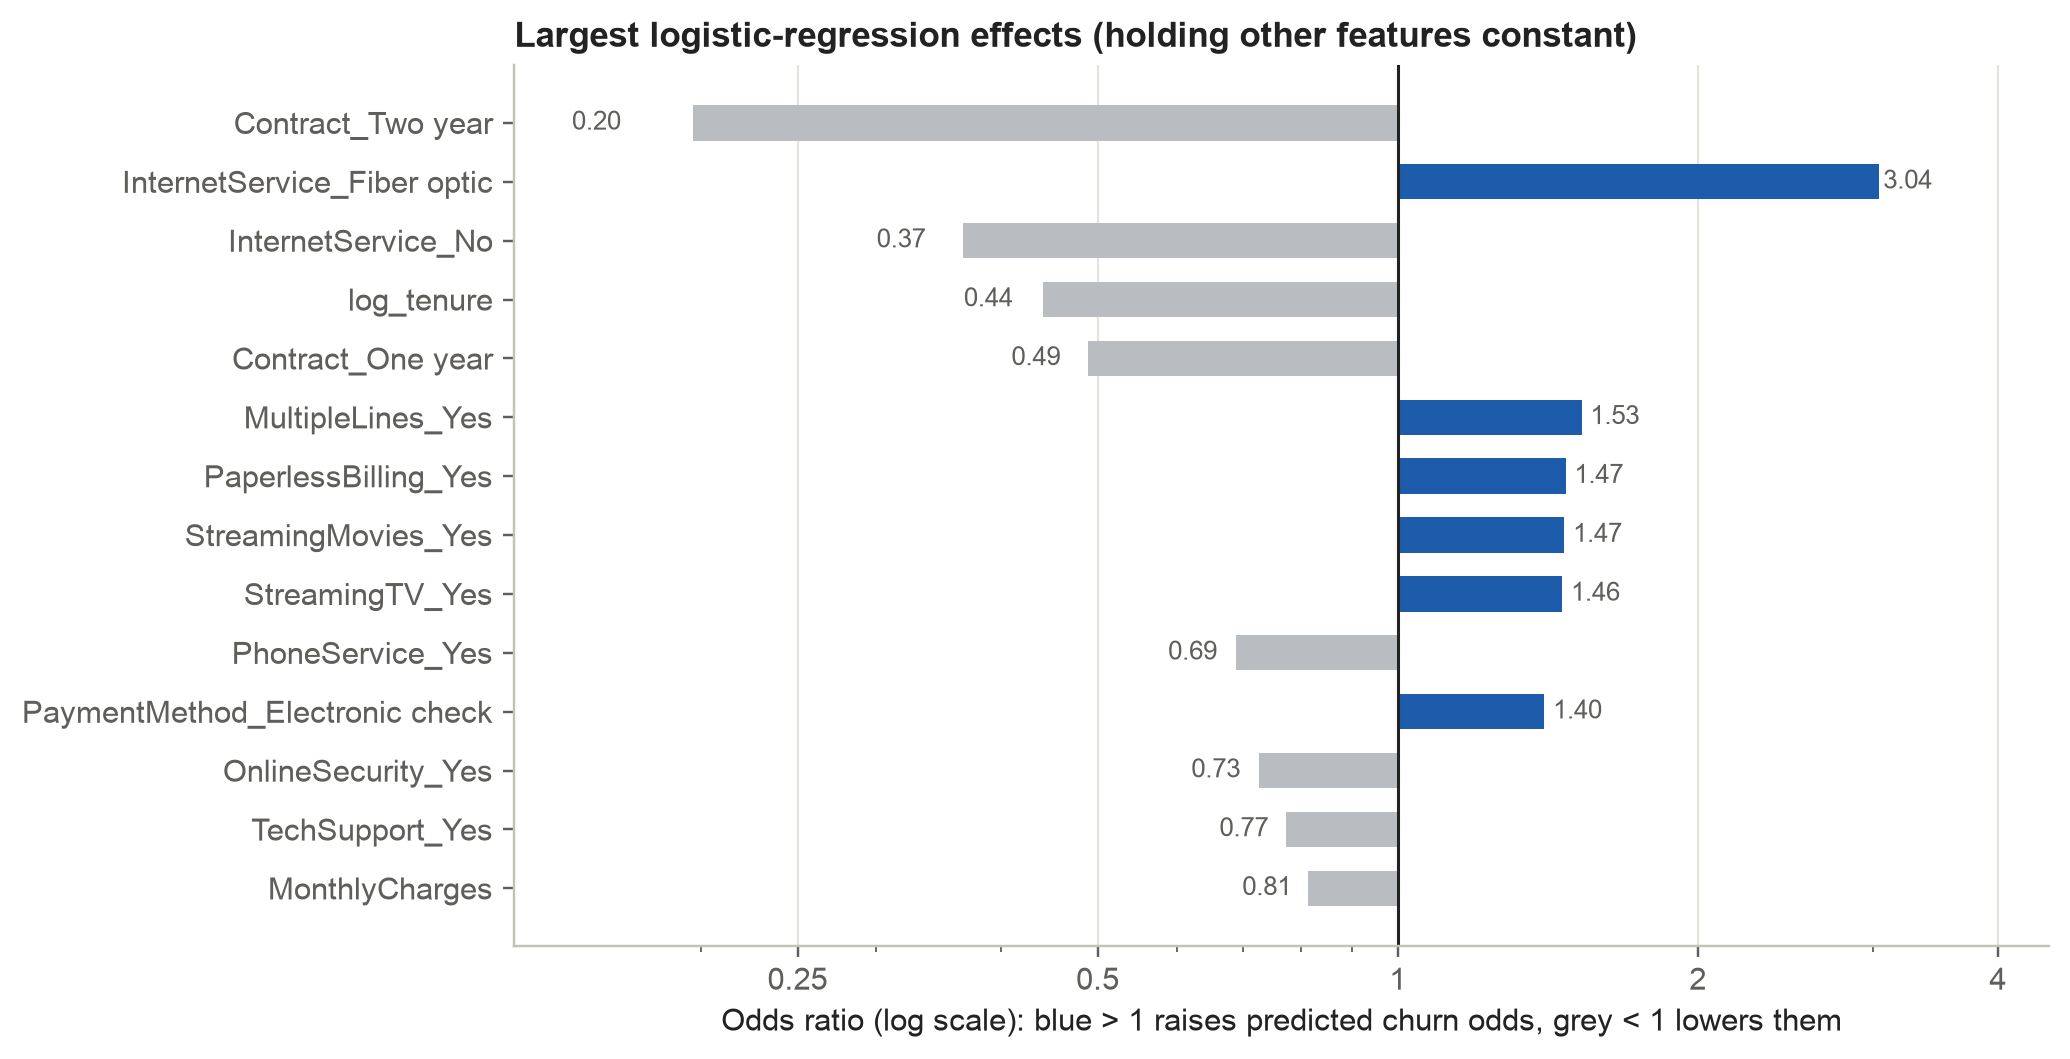

In [15]:
top = coefficients.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
colours = [CHURN_COLOR if c > 0 else RETAINED_COLOR for c in top["coefficient"]]
ax.barh(top["feature"], top["odds_ratio"] - 1, left=1, height=0.6, color=colours)
for position, ratio in enumerate(top["odds_ratio"]):
    ax.text(ratio + (0.03 if ratio > 1 else -0.03), position, f"{ratio:.2f}", va="center",
            ha="left" if ratio > 1 else "right", fontsize=8.5, color=MUTED_INK)
ax.axvline(1, color=INK, linewidth=1)
ax.set_xscale("log")
ax.set_xlim(0.13, 4.5)
ax.set_xticks([0.25, 0.5, 1, 2, 4])
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio (log scale): blue > 1 raises predicted churn odds, grey < 1 lowers them")
ax.set_title("Largest logistic-regression effects (holding other features constant)")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig4_5_logistic_odds_ratios.png")

### 9. Error analysis (test set, logistic regression at the chosen threshold)

In [16]:
analysis = X_test[["Contract", "InternetService", "tenure", "MonthlyCharges", "PaymentMethod"]].copy()
analysis["actual"] = y_test
analysis["probability"] = probabilities["Logistic regression"]
analysis["predicted"] = (analysis["probability"] >= best_threshold).astype(int)
analysis["outcome"] = np.select(
    [(analysis.actual == 1) & (analysis.predicted == 1), (analysis.actual == 0) & (analysis.predicted == 1),
     (analysis.actual == 1) & (analysis.predicted == 0)],
    ["True positive", "False positive", "False negative"], default="True negative")
analysis["tenure_band"] = pd.cut(analysis["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])


def segment_errors(column):
    grouped = analysis.groupby(column, observed=True)
    table = pd.DataFrame({
        "customers": grouped.size(),
        "churners": grouped["actual"].sum(),
        "recall": grouped.apply(lambda g: recall_score(g.actual, g.predicted) if g.actual.sum() else np.nan),
        "precision": grouped.apply(lambda g: precision_score(g.actual, g.predicted, zero_division=0)),
        "false_negatives": grouped.apply(lambda g: int(((g.actual == 1) & (g.predicted == 0)).sum())),
        "false_positives": grouped.apply(lambda g: int(((g.actual == 0) & (g.predicted == 1)).sum())),
    })
    return table


by_contract = segment_errors("Contract")
by_tenure = segment_errors("tenure_band")
display(by_contract.round(3))
display(by_tenure.round(3))

profile = analysis.groupby("outcome").agg(
    customers=("actual", "size"), median_tenure=("tenure", "median"),
    median_monthly_charge=("MonthlyCharges", "median"),
    month_to_month_share=("Contract", lambda s: (s == "Month-to-month").mean()),
    fibre_share=("InternetService", lambda s: (s == "Fiber optic").mean()),
    mean_probability=("probability", "mean"))
display(profile.round(3))

by_contract.to_csv(TABLE_DIR / "errors_by_contract.csv")
by_tenure.to_csv(TABLE_DIR / "errors_by_tenure_band.csv")
profile.to_csv(TABLE_DIR / "error_profiles.csv")
results["errors"] = {"by_contract": by_contract.round(4).to_dict("index"),
                     "by_tenure": by_tenure.round(4).to_dict("index"),
                     "profile": profile.round(4).to_dict("index")}

,customers,churners,recall,precision,false_negatives,false_positives
Contract,,,,,,
Month-to-month,773,329,0.812,0.573,62,199
One year,300,36,0.139,0.357,31,9
Two year,336,9,0.000,0.000,9,0


,customers,churners,recall,precision,false_negatives,false_positives
tenure_band,,,,,,
0-12,449,215,0.819,0.624,39,106
13-24,206,60,0.800,0.511,12,46
25-48,304,64,0.578,0.493,27,38
49-72,450,35,0.314,0.379,24,18


,customers,median_tenure,median_monthly_charge,month_to_month_share,fibre_share,mean_probability
outcome,,,,,,
False negative,102,24.5,60.125,0.608,0.363,0.192
False positive,208,12.0,80.625,0.957,0.764,0.522
True negative,827,47.0,55.800,0.296,0.244,0.098
True positive,272,5.0,79.075,0.982,0.790,0.618


Saved figure: outputs/figures/fig4_6_error_analysis_by_segment.png


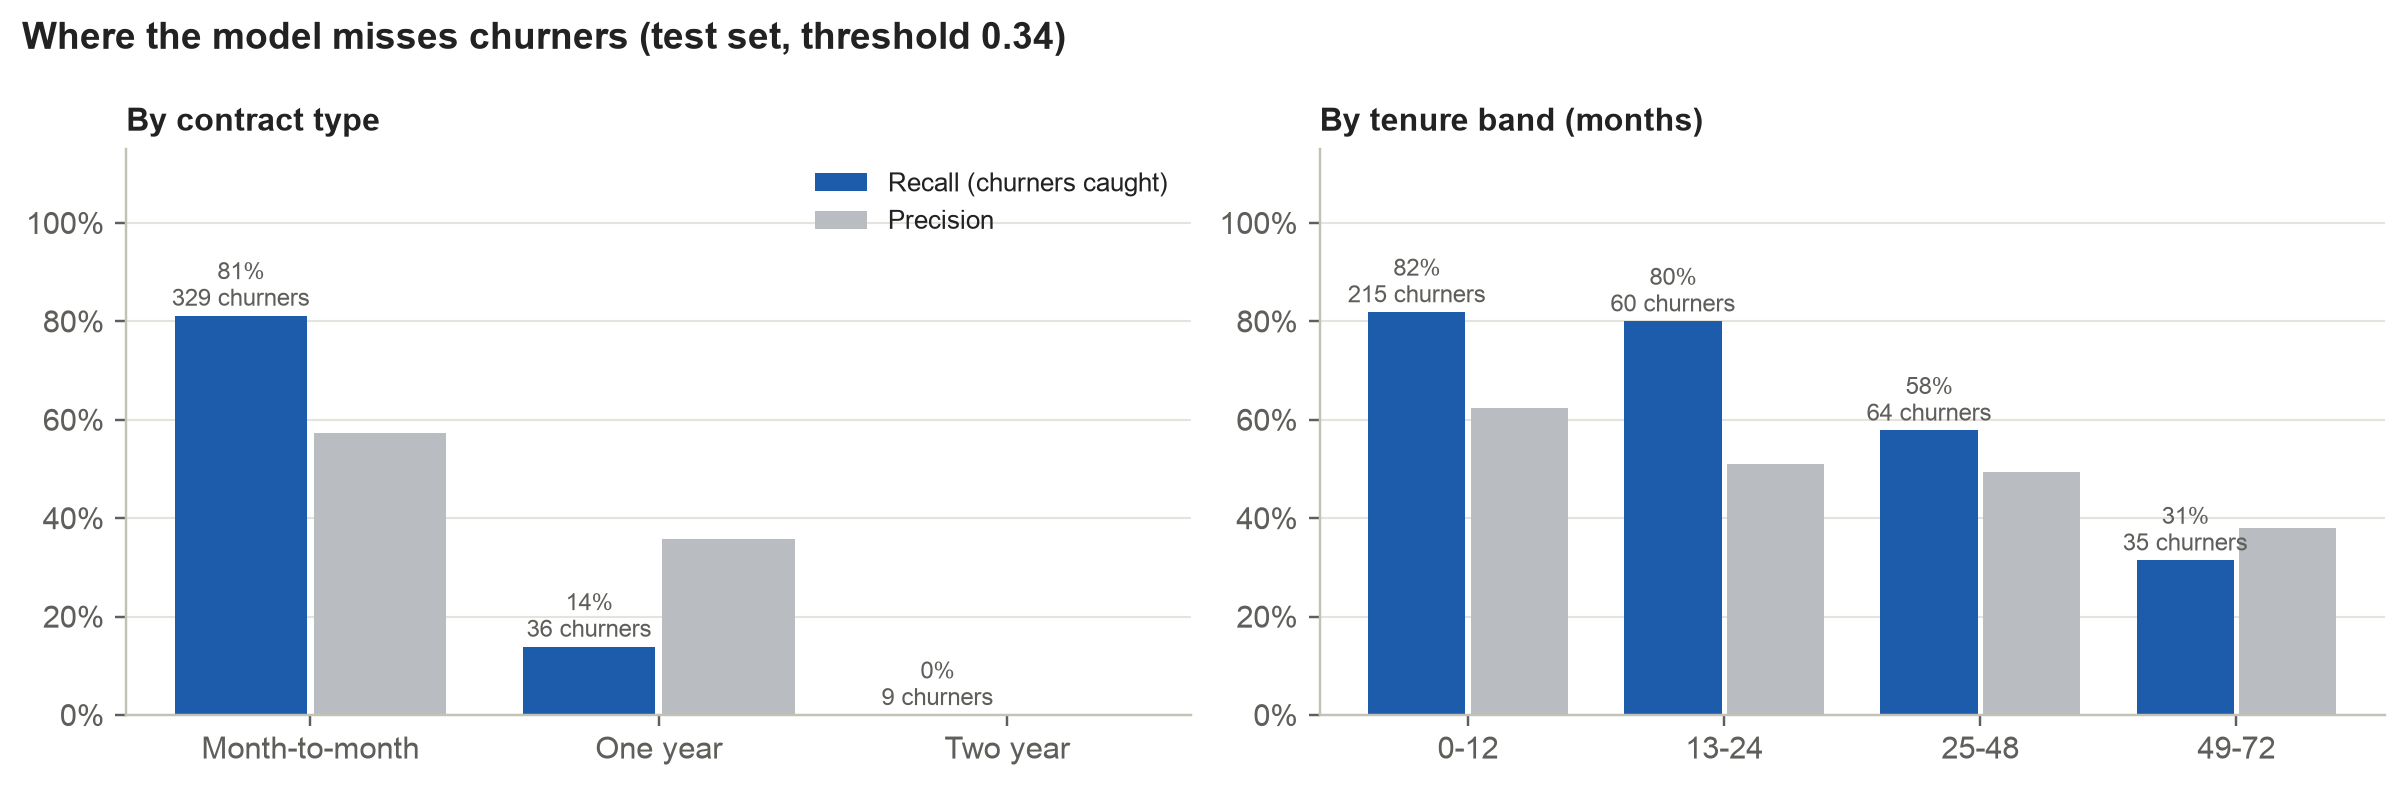

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, (table, title) in zip(axes, [(by_contract, "By contract type"), (by_tenure, "By tenure band (months)")]):
    positions = np.arange(len(table))
    ax.bar(positions - 0.2, table["recall"], width=0.38, color=CHURN_COLOR, label="Recall (churners caught)")
    ax.bar(positions + 0.2, table["precision"], width=0.38, color=RETAINED_COLOR, label="Precision")
    for x_pos, (recall, n_churn) in enumerate(zip(table["recall"], table["churners"])):
        ax.text(x_pos - 0.2, (0 if np.isnan(recall) else recall) + 0.02, f"{recall:.0%}\n{n_churn} churners",
                ha="center", fontsize=8, color=MUTED_INK)
    ax.set_xticks(positions)
    ax.set_xticklabels(table.index.astype(str))
    ax.set_ylim(0, 1.15)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set_title(title, fontsize=10.5)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle(f"Where the model misses churners (test set, threshold {best_threshold:.2f})", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save_figure(fig, "fig4_6_error_analysis_by_segment.png")

In [18]:
# Save test-set predictions (held-out customers only) for the Week 5 targeting analysis
test_predictions = X_test[["customerID", "Contract", "InternetService", "PaymentMethod", "tenure",
                           "MonthlyCharges", "OnlineSecurity", "TechSupport"]].copy()
test_predictions["actual"] = y_test
test_predictions["probability"] = probabilities["Logistic regression"]
test_predictions.to_csv(TABLE_DIR / "test_predictions.csv", index=False)
print(f"Saved outputs/tables/test_predictions.csv ({len(test_predictions):,} held-out customers)")

joblib.dump({"model": logistic, "threshold": best_threshold, "numeric": NUMERIC, "categorical": CATEGORICAL},
            MODEL_DIR / "logistic_regression_churn.joblib")
with open(RESULTS_DIR / "model_results.json", "w") as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved outputs/models/logistic_regression_churn.joblib and outputs/results/model_results.json")

Saved outputs/tables/test_predictions.csv (1,409 held-out customers)
Saved outputs/models/logistic_regression_churn.joblib and outputs/results/model_results.json
